# طبقه‌بندی تصاویر ماهواره‌ای EuroSAT با CNN از صفر
### End-to-End Computer Vision & Deep Learning Project

در این پروژه یک شبکه عصبی کانولوشنی اختصاصی (CNN) برای طبقه‌بندی ۱۰ نوع کاربری اراضی از تصاویر ماهواره‌ای EuroSAT می‌سازیم. از مدل pretrained یا Transfer Learning استفاده نمی‌شود.

**مسیر پروژه:** دانلود و اعتبارسنجی داده → تحلیل اکتشافی → تقسیم Stratified → Data Pipeline → Augmentation → طراحی CNN → آموزش → ارزیابی → تحلیل خطا → ذخیره و تست مدل.

> **نکته اجرا:** آماده‌سازی و تحلیل داده‌ها سبک‌تر از آموزش مدل هستند. در صورت نیاز می‌توانید ابتدا سلول‌ها را روی CPU اجرا و پس از آماده‌سازی، Runtime را روی GPU تغییر دهید. تغییر نوع Runtime در داخل Python انجام نمی‌شود.

## ۱) وارد کردن کتابخانه‌ها و تنظیم Seed

کتابخانه‌های موردنیاز را وارد می‌کنیم و Seed را برای افزایش قابلیت تکرارپذیری تنظیم می‌کنیم. در محیط‌های GPU، قابلیت تکرار کامل ممکن است بسته به عملیات و سخت‌افزار تضمین نشود.

In [1]:
import os
import json
import random
import shutil
import time
import zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError

import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Python seed / NumPy seed / TensorFlow seed configured.")
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Python seed / NumPy seed / TensorFlow seed configured.
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## ۲) دانلود و استخراج EuroSAT RGB

دانلود آرشیو از طریق `tf.keras.utils.get_file` انجام می‌شود. استخراج را با `zipfile` کنترل می‌کنیم تا ساختار داخلی آرشیو را بررسی و مسیر پوشه کلاس‌ها را مستقل از نام پوشه استخراج‌شده پیدا کنیم.

In [3]:
import zipfile
from pathlib import Path
import tensorflow as tf

# Alternative dataset source: Zenodo
DATASET_URL = (
    "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"
)

DOWNLOAD_DIR = Path("/content/datasets")
EXTRACT_DIR = DOWNLOAD_DIR / "EuroSAT_extracted"
ARCHIVE_PATH = DOWNLOAD_DIR / "EuroSAT_RGB.zip"

DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

try:
    downloaded_path = tf.keras.utils.get_file(
        fname="EuroSAT_RGB.zip",
        origin=DATASET_URL,
        cache_dir="/content",
        cache_subdir="datasets",
        extract=False,
        force_download=True
    )

    ARCHIVE_PATH = Path(downloaded_path)

    print("Archive downloaded successfully:")
    print(ARCHIVE_PATH)

except Exception as exc:
    raise RuntimeError(
        "دانلود EuroSAT از Zenodo نیز ناموفق بود. "
        "اتصال اینترنت Colab یا دسترسی به Zenodo را بررسی کنید."
    ) from exc


# Validate archive
if not ARCHIVE_PATH.exists() or ARCHIVE_PATH.stat().st_size == 0:
    raise FileNotFoundError(
        "فایل دیتاست دانلود نشده یا حجم فایل صفر است."
    )

if not zipfile.is_zipfile(ARCHIVE_PATH):
    raise ValueError(
        "فایل دانلودشده یک ZIP معتبر نیست."
    )

# Check archive integrity
with zipfile.ZipFile(ARCHIVE_PATH, "r") as zf:
    bad_member = zf.testzip()

    if bad_member is not None:
        raise RuntimeError(
            f"آرشیو خراب است؛ فایل مشکل‌دار: {bad_member}"
        )

    zf.extractall(EXTRACT_DIR)

print("Extraction completed successfully.")
print("Dataset extraction path:", EXTRACT_DIR)

94658721/94658721 ━━━━━━━━━━━━━━━━━━━━ 57s 1us/step
Archive downloaded successfully:
/content/datasets/EuroSAT_RGB.zip
Extraction completed successfully.
Dataset extraction path: /content/datasets/EuroSAT_extracted


## ۳) شناسایی ساختار دیتاست و بررسی سلامت تصاویر

مسیر پوشه کلاس‌ها را با جستجوی پوشه‌ای که زیرپوشه‌های کلاس مورد انتظار را دارد پیدا می‌کنیم؛ بنابراین به مسیر ثابت `/content/2750` وابسته نیستیم. فایل‌های تصویر معتبر بررسی می‌شوند و تصاویر خراب یا غیرقابل‌خواندن از مجموعه نمونه‌ها کنار گذاشته شده و گزارش می‌شوند.

In [4]:
EXPECTED_CLASSES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
    "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"
]
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def find_dataset_root(extract_root: Path, expected_classes):
    expected = set(expected_classes)
    candidates = []
    for current, dirs, _ in os.walk(extract_root):
        if expected.issubset(set(dirs)):
            candidates.append(Path(current))
    if not candidates:
        raise FileNotFoundError(
            "پوشه‌ای که هر ۱۰ کلاس مورد انتظار را داشته باشد پیدا نشد. "
            "ساختار استخراج‌شده را بررسی کنید."
        )
    # Prefer the shallowest candidate to avoid nested duplicate matches.
    return sorted(candidates, key=lambda p: len(p.parts))[0]

DATASET_ROOT = find_dataset_root(EXTRACT_DIR, EXPECTED_CLASSES)
class_dirs = sorted([p.name for p in DATASET_ROOT.iterdir() if p.is_dir()])
print("Dataset root:", DATASET_ROOT)
print("Detected class folders:", class_dirs)
assert set(EXPECTED_CLASSES).issubset(set(class_dirs)), "کلاس‌های مورد انتظار کامل نیستند."
assert len(EXPECTED_CLASSES) == 10, "تعداد کلاس‌های مورد انتظار باید ۱۰ باشد."

def collect_and_validate_images(dataset_root: Path, class_names):
    records, corrupt_files, unexpected_files, empty_classes = [], [], [], []
    for class_name in class_names:
        folder = dataset_root / class_name
        if not folder.exists():
            empty_classes.append(class_name)
            continue
        files = sorted(folder.iterdir())
        class_valid_count = 0
        for file_path in files:
            if not file_path.is_file():
                continue
            if file_path.suffix.lower() not in VALID_EXTENSIONS:
                unexpected_files.append(str(file_path))
                continue
            try:
                with Image.open(file_path) as img:
                    img.verify()
                with Image.open(file_path) as img:
                    if img.mode not in ("RGB", "RGBA", "L"):
                        img.convert("RGB")
                records.append((str(file_path), class_name))
                class_valid_count += 1
            except (UnidentifiedImageError, OSError, ValueError) as err:
                corrupt_files.append((str(file_path), repr(err)))
        if class_valid_count == 0:
            empty_classes.append(class_name)
    return records, corrupt_files, unexpected_files, empty_classes

image_records, corrupt_images, unexpected_files, empty_classes = collect_and_validate_images(
    DATASET_ROOT, EXPECTED_CLASSES
)
print(f"Valid images: {len(image_records):,}")
print(f"Corrupt/unreadable images: {len(corrupt_images)}")
print(f"Unexpected non-image files: {len(unexpected_files)}")
print(f"Empty classes: {empty_classes}")

if corrupt_images:
    print("\nCorrupt image paths (first 10):")
    for path, error in corrupt_images[:10]:
        print(path, "->", error)
if unexpected_files:
    print("\nUnexpected files (first 10):")
    print(*unexpected_files[:10], sep="\n")

assert len(image_records) > 0, "هیچ تصویر سالمی یافت نشد."
assert not empty_classes, f"کلاس خالی یا بدون تصویر سالم: {empty_classes}"

Dataset root: /content/datasets/EuroSAT_extracted/EuroSAT_RGB
Detected class folders: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Valid images: 27,000
Corrupt/unreadable images: 0
Unexpected non-image files: 0
Empty classes: []


## ۴) تحلیل توزیع کلاس‌ها (EDA)

تابع شمارش، تعداد تصاویر سالم هر کلاس را از روی فهرست اعتبارسنجی‌شده محاسبه می‌کند. سپس نمودار و شاخص‌های توازن داده را می‌سازیم. توازن صرفاً بر اساس تعداد نمونه‌ها بررسی می‌شود و به معنی یکسان بودن دشواری کلاس‌ها نیست.

In [5]:
VALID_IMAGE_PATHS = {Path(path).resolve() for path, _ in image_records}

def count_class_distribution(data_path: str) -> pd.DataFrame:
    root = Path(data_path).resolve()
    counts = {}
    for class_name in EXPECTED_CLASSES:
        class_folder = root / class_name
        counts[class_name] = sum(
            1 for p in class_folder.iterdir()
            if p.is_file()
            and p.suffix.lower() in VALID_EXTENSIONS
            and p.resolve() in VALID_IMAGE_PATHS
        ) if class_folder.exists() else 0
    return pd.DataFrame({"Class": list(counts.keys()), "Image_Count": list(counts.values())})

df_counts = count_class_distribution(str(DATASET_ROOT))
display(df_counts)

,Class,Image_Count
0,AnnualCrop,3000
1,Forest,3000
2,HerbaceousVegetation,3000
3,Highway,2500
4,Industrial,2500
5,Pasture,2000
6,PermanentCrop,2500
7,Residential,3000
8,River,2500
9,SeaLake,3000


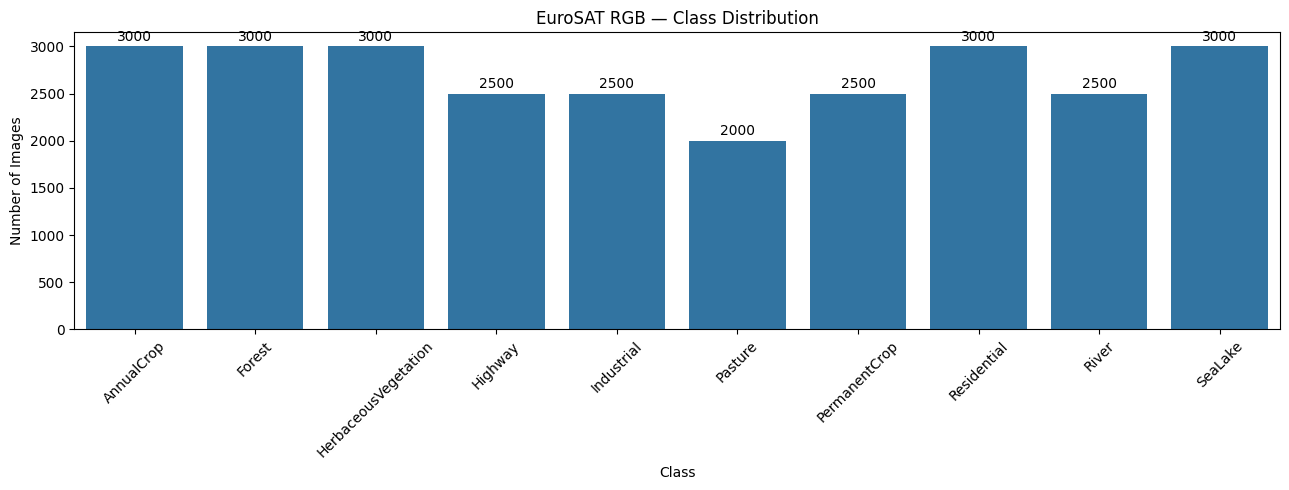

Balanced by sample count: False
Minimum: 2,000 | Maximum: 3,000 | Difference: 1,000
Mean: 2,700.00 | Std: 331.66
Imbalance ratio (max/min): 1.500
Total valid samples: 27,000
Number of classes: 10


In [6]:
def plot_and_analyze_distribution(df_counts: pd.DataFrame) -> bool:
    if not {"Class", "Image_Count"}.issubset(df_counts.columns):
        raise ValueError("DataFrame باید ستون‌های Class و Image_Count داشته باشد.")
    fig, ax = plt.subplots(figsize=(13, 5))
    sns.barplot(data=df_counts, x="Class", y="Image_Count", ax=ax)
    ax.set_title("EuroSAT RGB — Class Distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of Images")
    ax.tick_params(axis="x", rotation=45)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=2)
    plt.tight_layout()
    plt.show()

    values = df_counts["Image_Count"].to_numpy()
    is_balanced = len(np.unique(values)) == 1
    print("Balanced by sample count:", is_balanced)
    if len(values):
        print(f"Minimum: {values.min():,} | Maximum: {values.max():,} | Difference: {values.max()-values.min():,}")
        print(f"Mean: {values.mean():,.2f} | Std: {values.std():,.2f}")
        ratio = values.max() / values.min() if values.min() else np.inf
        print(f"Imbalance ratio (max/min): {ratio:.3f}")
    return bool(is_balanced)

is_dataset_balanced = plot_and_analyze_distribution(df_counts)
total_samples = int(df_counts["Image_Count"].sum())
print(f"Total valid samples: {total_samples:,}")
print(f"Number of classes: {df_counts['Class'].nunique()}")

## ۵) نمایش نمونه تصاویر

برای هر کلاس، یک نمونه واقعی نمایش داده می‌شود. تصاویر RGB هستند و برای نمایش، صرفاً در صورت نیاز به RGB تبدیل می‌شوند.

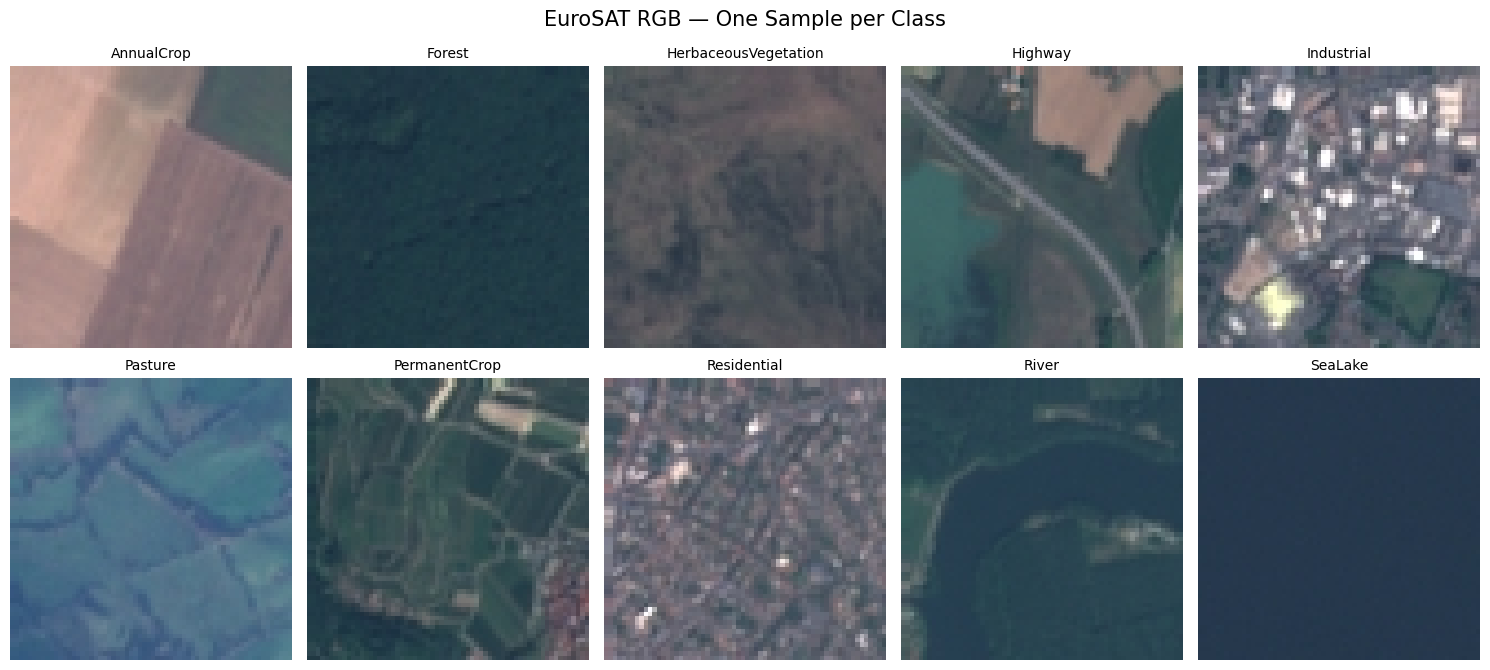

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for ax, class_name in zip(axes.flat, EXPECTED_CLASSES):
    candidates = [Path(p) for p, label in image_records if label == class_name]
    sample_path = random.choice(candidates)
    with Image.open(sample_path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(class_name, fontsize=10)
    ax.axis("off")
plt.suptitle("EuroSAT RGB — One Sample per Class", fontsize=15)
plt.tight_layout()
plt.show()

## ۶) تقسیم Stratified به Train / Validation / Test

تقسیم 70/15/15 با دو مرحله `train_test_split` و `stratify` انجام می‌شود. این روش توزیع کلاس‌ها را تا حد امکان در هر بخش حفظ می‌کند. Test تا پایان انتخاب مدل کنار گذاشته می‌شود.

In [8]:
paths = np.array([record[0] for record in image_records])
labels = np.array([record[1] for record in image_records])

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    paths, labels,
    test_size=(1 - 0.70),
    random_state=SEED,
    stratify=labels
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

# Verify that partitions are mutually exclusive and cover all samples.
train_set, val_set, test_set = set(train_paths), set(val_paths), set(test_paths)
assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)
assert len(train_paths) + len(val_paths) + len(test_paths) == len(paths)
assert set(train_labels) == set(EXPECTED_CLASSES)
assert set(val_labels) == set(EXPECTED_CLASSES)
assert set(test_labels) == set(EXPECTED_CLASSES)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Samples": [len(train_paths), len(val_paths), len(test_paths)],
    "Actual_Ratio": [
        len(train_paths)/len(paths), len(val_paths)/len(paths), len(test_paths)/len(paths)
    ]
})
display(split_summary)

,Split,Samples,Actual_Ratio
0,Train,18899,0.699963
1,Validation,4050,0.150000
2,Test,4051,0.150037


In [9]:
split_counts = pd.DataFrame({
    "Train": pd.Series(Counter(train_labels)),
    "Validation": pd.Series(Counter(val_labels)),
    "Test": pd.Series(Counter(test_labels))
}).fillna(0).astype(int).reindex(EXPECTED_CLASSES)
split_counts.index.name = "Class"
display(split_counts)

# Proportions per class, useful to confirm stratification.
split_props = split_counts.div(split_counts.sum(axis=0), axis=1)
display(split_props.round(3))

,Train,Validation,Test
Class,,,
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2099,450,451
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375


,Train,Validation,Test
Class,,,
AnnualCrop,0.111,0.111,0.111
Forest,0.111,0.111,0.111
HerbaceousVegetation,0.111,0.111,0.111
Highway,0.093,0.093,0.093
Industrial,0.093,0.093,0.093
Pasture,0.074,0.074,0.074
PermanentCrop,0.093,0.093,0.093
Residential,0.111,0.111,0.111
River,0.093,0.093,0.093


## ۷) ساخت پوشه‌های Train / Validation / Test

داده‌ها را در ساختار پوشه‌ای جداگانه قرار می‌دهیم تا بارگذاری Keras آسان و قابل بررسی باشد. کپی‌کردن فایل‌ها به فضای Colab نیازمند فضای دیسک اضافی است؛ در صورت کمبود فضا، خطا را بررسی کنید و از ایجاد چند نسخه غیرضروری دیتاست اجتناب کنید.

In [10]:
SPLIT_ROOT = Path("/content/eurosat_split")
if SPLIT_ROOT.exists():
    shutil.rmtree(SPLIT_ROOT)
for split_name in ("train", "validation", "test"):
    for class_name in EXPECTED_CLASSES:
        (SPLIT_ROOT / split_name / class_name).mkdir(parents=True, exist_ok=True)

def copy_partition(file_paths, file_labels, split_name):
    for src, class_name in zip(file_paths, file_labels):
        src_path = Path(src)
        dest = SPLIT_ROOT / split_name / class_name / src_path.name
        if dest.exists():
            raise FileExistsError(f"Duplicate destination file: {dest}")
        shutil.copy2(src_path, dest)

copy_partition(train_paths, train_labels, "train")
copy_partition(val_paths, val_labels, "validation")
copy_partition(test_paths, test_labels, "test")

for split_name in ("train", "validation", "test"):
    split_dir = SPLIT_ROOT / split_name
    observed = sorted(p.name for p in split_dir.iterdir() if p.is_dir())
    assert set(observed) == set(EXPECTED_CLASSES)
    count_on_disk = sum(
        1 for class_dir in split_dir.iterdir() for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )
    print(f"{split_name}: {count_on_disk:,} images")

train: 18,899 images
validation: 4,050 images
test: 4,051 images


## ۸) پیکربندی Hyperparameters

تنظیمات اصلی پروژه در یک سلول نگهداری می‌شوند تا تغییر آن‌ها در مراحل بعدی آسان باشد.

In [11]:
IMG_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 40
LEARNING_RATE = 1e-3
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(EXPECTED_CLASSES)

assert abs(TRAIN_RATIO + VALIDATION_RATIO + TEST_RATIO - 1.0) < 1e-8
print("Configuration initialized.")

Configuration initialized.


## ۹) بارگذاری Dataset با Keras

هر سه split جداگانه بارگذاری می‌شوند. Shuffle فقط برای Train فعال است. ترتیب کلاس‌ها به‌صورت ثابت به Keras داده می‌شود تا label indexها در تمام splitها یکسان باشند.

In [12]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    SPLIT_ROOT / "train",
    labels="inferred",
    label_mode="int",
    class_names=EXPECTED_CLASSES,
    color_mode="rgb",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)
val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    SPLIT_ROOT / "validation",
    labels="inferred",
    label_mode="int",
    class_names=EXPECTED_CLASSES,
    color_mode="rgb",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)
test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    SPLIT_ROOT / "test",
    labels="inferred",
    label_mode="int",
    class_names=EXPECTED_CLASSES,
    color_mode="rgb",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

# image_dataset_from_directory returns a Dataset; use the explicit class_names order passed at load time.
class_names = EXPECTED_CLASSES.copy()
print("Class names:", class_names)
assert len(class_names) == NUM_CLASSES
assert all((SPLIT_ROOT / split / cls).exists() for split in ("train", "validation", "test") for cls in class_names)

for images, labels_batch in train_ds_raw.take(1):
    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels_batch.shape)
    print("Pixel range before normalization:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

Found 18899 files belonging to 10 classes.
Found 4050 files belonging to 10 classes.
Found 4051 files belonging to 10 classes.
Class names: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Batch image shape: (32, 64, 64, 3)
Batch label shape: (32,)
Pixel range before normalization: 19.0 255.0


## ۱۰) Data Augmentation

Flip و چرخش محدود و Zoom متوسط استفاده می‌شود. برای تصاویر ماهواره‌ای، چرخش و تغییر جهت در بسیاری از کلاس‌ها معنی کاربری را تغییر نمی‌دهد، اما هر augmentation باید همچنان تصویر معناداری ایجاد کند. این لایه در مدل قرار می‌گیرد و در inference غیرفعال است.

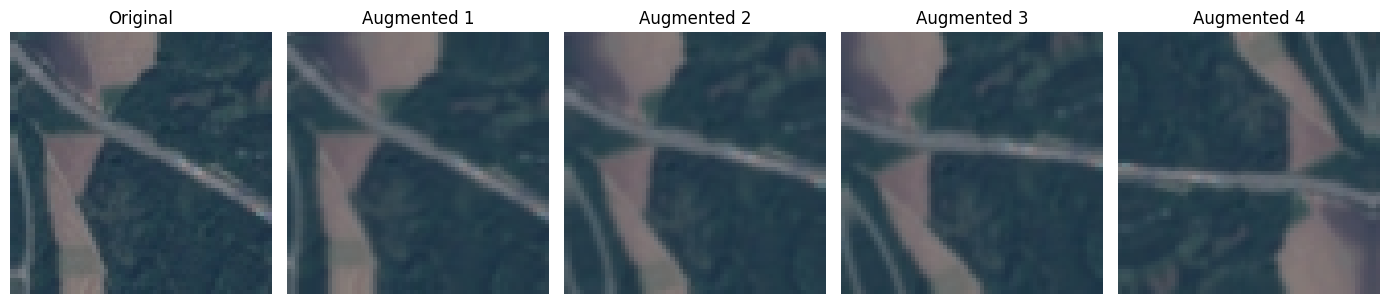

In [13]:
augmentation_layer = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(factor=0.10),
    keras.layers.RandomZoom(height_factor=0.10, width_factor=0.10),
], name="data_augmentation")

# Visualize a few augmented views of a training image.
sample_images, sample_labels = next(iter(train_ds_raw.take(1)))
sample_image = sample_images[0:1]
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(sample_image[0].numpy().astype("uint8"))
axes[0].set_title("Original")
axes[0].axis("off")
for i in range(1, 5):
    aug = augmentation_layer(sample_image, training=True)[0]
    axes[i].imshow(tf.clip_by_value(aug, 0, 255).numpy().astype("uint8"))
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

## ۱۱) بهینه‌سازی TensorFlow Data Pipeline

از cache دیسکی برای جلوگیری از مصرف زیاد RAM استفاده می‌کنیم و prefetch را برای آماده‌سازی batchهای بعدی فعال می‌کنیم. Cache فقط در مرحله بارگذاری تصاویر و resize است؛ augmentation داخل مدل قرار دارد و در هر batch آموزشی به‌صورت تصادفی اجرا می‌شود.

In [14]:
CACHE_DIR = Path("/content/tf_cache")
CACHE_DIR.mkdir(exist_ok=True)

def prepare_dataset(ds, split_name, cache_to_disk=True):
    if cache_to_disk:
        cache_path = str(CACHE_DIR / split_name)
        ds = ds.cache(cache_path)
    else:
        ds = ds.cache()
    if split_name == "train":
        ds = ds.shuffle(
            buffer_size=min(len(train_paths), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    return ds.prefetch(AUTOTUNE)

train_ds = prepare_dataset(train_ds_raw, "train")
val_ds = prepare_dataset(val_ds_raw, "validation")
test_ds = prepare_dataset(test_ds_raw, "test")

print("Data pipelines prepared with disk cache and prefetch.")

Data pipelines prepared with disk cache and prefetch.


## ۱۲) ساخت معماری CNN از صفر

مدل شامل چند بلوک Conv2D با BatchNormalization و ReLU، سپس MaxPooling و Dropout است. در پایان از GlobalAveragePooling2D و Dense Softmax برای طبقه‌بندی ۱۰ کلاس استفاده می‌کنیم. نرمال‌سازی پیکسل درون مدل انجام می‌شود تا هنگام ذخیره و inference نیز بخشی از مدل باشد.

In [15]:
def build_model(input_shape, num_classes, augmentation_layer):
    inputs = keras.Input(shape=input_shape, name="satellite_rgb")

    x = augmentation_layer(inputs)
    x = keras.layers.Rescaling(1.0 / 255.0, name="pixel_normalization")(x)

    for filters, dropout_rate in [(32, 0.15), (64, 0.20), (128, 0.25), (256, 0.30)]:
        x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.Activation("relu")(x)

        x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.Activation("relu")(x)

        x = keras.layers.MaxPooling2D(pool_size=2)(x)
        x = keras.layers.Dropout(dropout_rate)(x)

    x = keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = keras.layers.Dense(128, activation="relu", name="feature_dense")(x)
    x = keras.layers.Dropout(0.35, name="head_dropout")(x)
    outputs = keras.layers.Dense(num_classes, activation="softmax", name="class_probabilities")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="EuroSAT_Custom_CNN")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )
    return model

model = build_model((IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, augmentation_layer)
model.summary()

Model: "EuroSAT_Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ satellite_rgb (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pixel_normalization (Rescaling) │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,209,322 (4.61 MB)

 Trainable params: 1,207,402 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [16]:
# Optional architecture diagram; notebook continues if plotting utility fails.
try:
    keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, dpi=70)
except Exception as exc:
    print("Architecture diagram could not be rendered:", exc)

## ۱۳) تعریف Callbackها

- `ModelCheckpoint`: ذخیره بهترین مدل بر اساس `val_accuracy`.
- `EarlyStopping`: توقف آموزش در صورت عدم بهبود `val_loss` و بازگرداندن وزن‌های بهترین epoch.
- `ReduceLROnPlateau`: کاهش نرخ یادگیری در صورت توقف پیشرفت validation loss.

In [17]:
MODEL_DIR = Path("/content/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = MODEL_DIR / "eurosat_cnn_best.keras"

model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(CHECKPOINT_PATH),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=8,
    restore_best_weights=True,
    verbose=1
)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)
callbacks_list = [model_checkpoint, early_stopping, reduce_lr]
print("Callbacks ready.")

Callbacks ready.


## ۱۴) بررسی‌های پیش از آموزش

پیش از شروع آموزش، تعداد batchها، شکل ورودی و خروجی مدل و در دسترس بودن GPU بررسی می‌شود. GPU در صورت ارائه توسط Colab استفاده خواهد شد؛ دسترسی GPU تضمین‌شده نیست.

In [18]:
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
assert model.input_shape == (None, IMG_SIZE, IMG_SIZE, 3)
assert model.output_shape[-1] == NUM_CLASSES
assert tf.data.experimental.cardinality(train_ds).numpy() > 0
assert tf.data.experimental.cardinality(val_ds).numpy() > 0
assert tf.data.experimental.cardinality(test_ds).numpy() > 0

Train batches: 591
Validation batches: 127
Test batches: 127
Model input: (None, 64, 64, 3)
Model output: (None, 10)
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## ۱۵) آموزش مدل

این سلول آموزش را آغاز می‌کند. نتایج History فقط پس از اجرای واقعی این سلول در Colab ایجاد می‌شوند. آموزش روی Train انجام می‌شود و Validation برای پایش عملکرد و callbackها استفاده می‌شود؛ Test در این مرحله وارد آموزش نمی‌شود.

In [19]:
start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)
training_seconds = time.time() - start_time
print(f"Training time: {training_seconds/60:.2f} minutes")
print("Epochs completed:", len(history.history.get("loss", [])))
print("Best validation accuracy:", max(history.history.get("val_accuracy", [float("nan")])))
print("Best validation loss:", min(history.history.get("val_loss", [float("nan")])))

Epoch 1/40
591/591 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5305 - loss: 1.3407
Epoch 1: val_accuracy improved from None to 0.54889, saving model to /content/models/eurosat_cnn_best.keras

Epoch 1: finished saving model to /content/models/eurosat_cnn_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 37s 36ms/step - accuracy: 0.6101 - loss: 1.1135 - val_accuracy: 0.5489 - val_loss: 1.3891 - learning_rate: 0.0010
Epoch 2/40
591/591 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7107 - loss: 0.8318
Epoch 2: val_accuracy improved from 0.54889 to 0.71704, saving model to /content/models/eurosat_cnn_best.keras

Epoch 2: finished saving model to /content/models/eurosat_cnn_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 21s 33ms/step - accuracy: 0.7285 - loss: 0.7904 - val_accuracy: 0.7170 - val_loss: 0.7953 - learning_rate: 0.0010
Epoch 3/40
591/591 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7642 - loss: 0.6870
Epoch 3: val_accuracy improved from 0.71704 to 0.72321, saving model to /content/model

## ۱۶) نمودار Accuracy و Loss

Accuracy و Loss آموزش و Validation را در نمودارهای مستقل بررسی می‌کنیم. فاصله بین منحنی‌ها می‌تواند نشانه‌ای از overfitting باشد؛ تفسیر نهایی باید بر اساس منحنی‌های واقعی باشد.

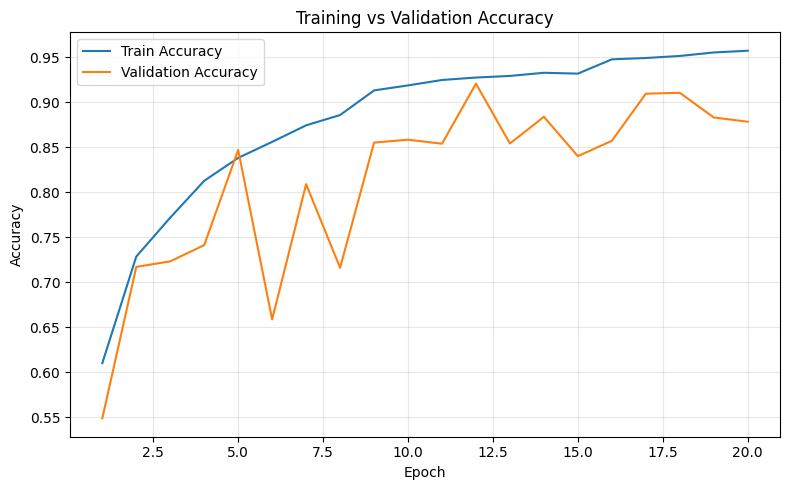

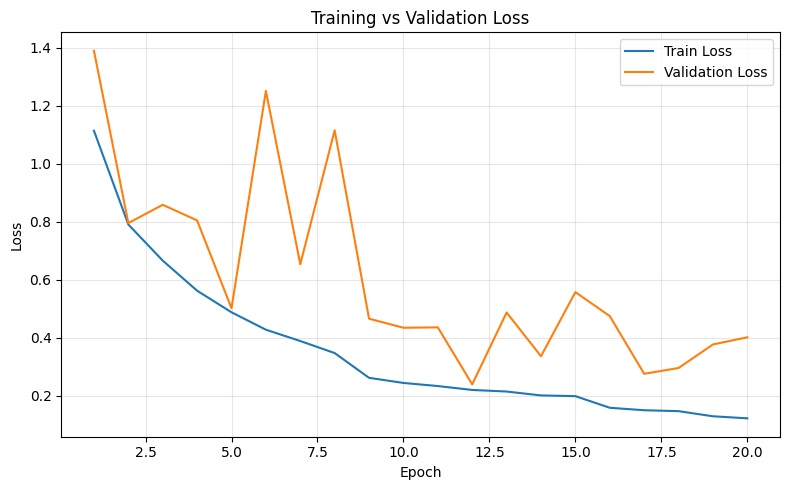

In [20]:
history_dict = history.history
epochs_ran = range(1, len(history_dict["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history_dict["accuracy"], label="Train Accuracy")
plt.plot(epochs_ran, history_dict["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history_dict["loss"], label="Train Loss")
plt.plot(epochs_ran, history_dict["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## ۱۷) ارزیابی نهایی روی Test

Test set فقط برای ارزیابی نهایی استفاده می‌شود. پس از این مرحله، نتایج Test برای تصمیم‌گیری درباره تغییر معماری یا hyperparameterها استفاده نخواهد شد تا ارزیابی مستقل باقی بماند.

In [21]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

127/127 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9269 - loss: 0.2352
Test loss: 0.2352
Test accuracy: 0.9269


## ۱۸) گزارش Classification و استخراج پیش‌بینی‌ها

برای داده‌های Test، برچسب واقعی، کلاس پیش‌بینی‌شده و احتمال هر کلاس استخراج می‌شود. به دلیل shuffle خاموش در Test، ترتیب نمونه‌ها ثابت و قابل ردیابی است.

In [22]:
# Directory-loader order: class_names order, then lexicographic filename order.
test_paths_ordered = [
    str(path)
    for class_name in class_names
    for path in sorted((SPLIT_ROOT / "test" / class_name).glob("*"))
    if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
]
test_labels_ordered = np.array([
    class_names.index(Path(path).parent.name) for path in test_paths_ordered
])
y_true_batches = []
y_prob_batches = []
for images, labels_batch in test_ds:
    probs = model.predict(images, verbose=0)
    y_true_batches.append(labels_batch.numpy())
    y_prob_batches.append(probs)

y_true = np.concatenate(y_true_batches)
y_prob = np.concatenate(y_prob_batches)
y_pred = np.argmax(y_prob, axis=1)
confidence = np.max(y_prob, axis=1)

assert len(y_true) == len(y_pred) == len(test_paths_ordered)
assert np.array_equal(y_true, test_labels_ordered)
assert y_prob.shape == (len(y_true), NUM_CLASSES)
assert np.allclose(y_prob.sum(axis=1), 1.0, atol=1e-5)

report_dict = classification_report(
    y_true, y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report_dict).T
display(report_df.round(4))
print(classification_report(
    y_true, y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))

,precision,recall,f1-score,support
AnnualCrop,0.8936,0.9333,0.9130,450.0000
Forest,0.9158,0.9911,0.9520,450.0000
HerbaceousVegetation,0.8979,0.8381,0.8670,451.0000
Highway,0.9404,0.9680,0.9540,375.0000
Industrial,0.9730,0.9600,0.9664,375.0000
Pasture,0.9910,0.7333,0.8429,300.0000
PermanentCrop,0.8658,0.9120,0.8883,375.0000
Residential,0.9028,0.9911,0.9449,450.0000
River,0.9322,0.9173,0.9247,375.0000
SeaLake,0.9977,0.9689,0.9831,450.0000


                      precision    recall  f1-score   support

          AnnualCrop       0.89      0.93      0.91       450
              Forest       0.92      0.99      0.95       450
HerbaceousVegetation       0.90      0.84      0.87       451
             Highway       0.94      0.97      0.95       375
          Industrial       0.97      0.96      0.97       375
             Pasture       0.99      0.73      0.84       300
       PermanentCrop       0.87      0.91      0.89       375
         Residential       0.90      0.99      0.94       450
               River       0.93      0.92      0.92       375
             SeaLake       1.00      0.97      0.98       450

            accuracy                           0.93      4051
           macro avg       0.93      0.92      0.92      4051
        weighted avg       0.93      0.93      0.93      4051



## ۱۹) Confusion Matrix

ماتریس درهم‌ریختگی نشان می‌دهد مدل هر کلاس را با چه کلاس‌هایی اشتباه می‌گیرد. خانه‌های قطر اصلی پیش‌بینی صحیح هستند و مقادیر خارج از قطر خطاها را نشان می‌دهند.

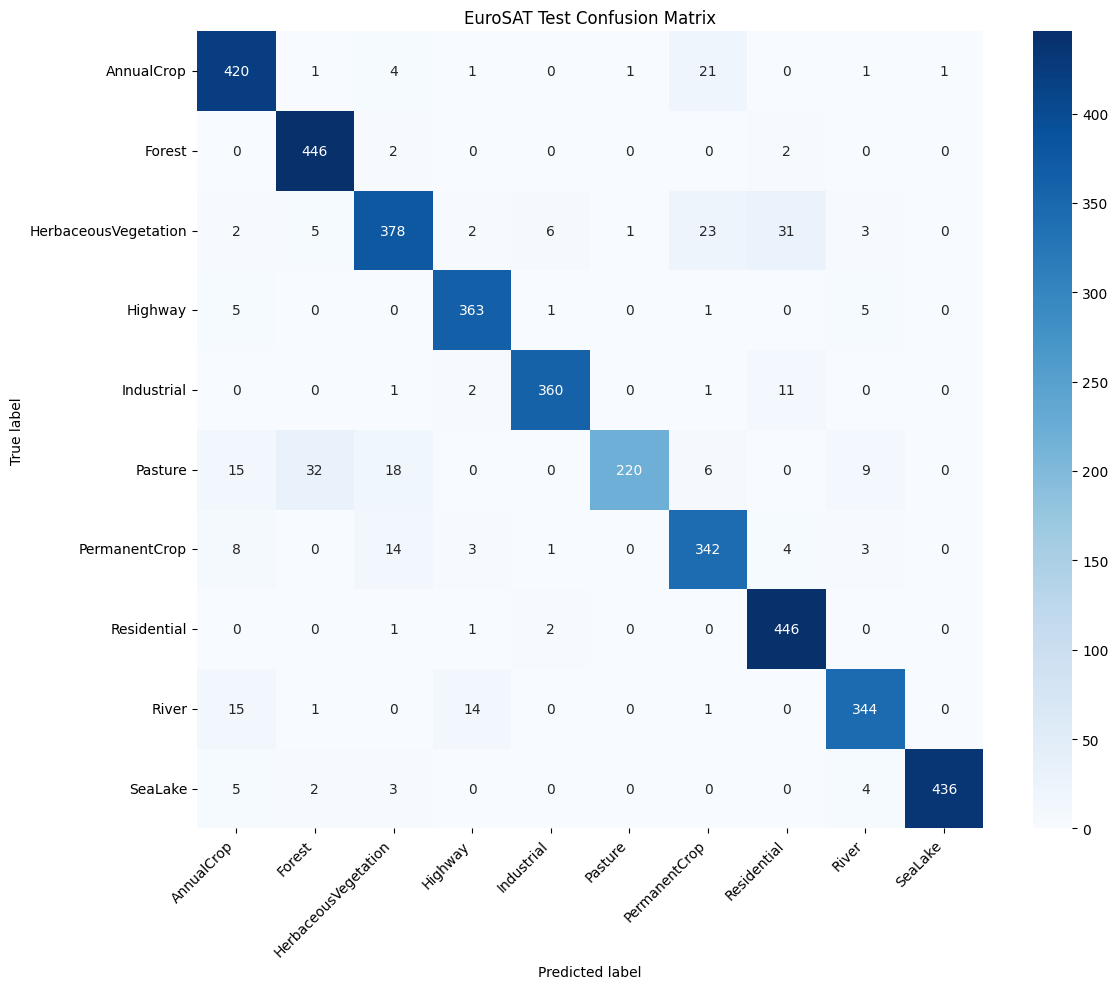

,precision,recall,f1-score,support
Pasture,0.991,0.733,0.843,300.0
HerbaceousVegetation,0.898,0.838,0.867,451.0
PermanentCrop,0.866,0.912,0.888,375.0
AnnualCrop,0.894,0.933,0.913,450.0
River,0.932,0.917,0.925,375.0
Residential,0.903,0.991,0.945,450.0
Forest,0.916,0.991,0.952,450.0
Highway,0.940,0.968,0.954,375.0
Industrial,0.973,0.960,0.966,375.0
SeaLake,0.998,0.969,0.983,450.0


In [23]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.title("EuroSAT Test Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Class-wise metrics table for concise comparison
class_metrics = report_df.loc[class_names, ["precision", "recall", "f1-score", "support"]]
display(class_metrics.sort_values("f1-score", ascending=True).round(3))

## ۲۰) تحلیل خطا (Error Analysis)

نمونه‌های اشتباه واقعی از Test نمایش داده می‌شوند. برای هر نمونه، کلاس واقعی، کلاس پیش‌بینی‌شده و confidence نشان داده می‌شود. اگر مدل هیچ خطایی نداشته باشد، پیام مناسب نمایش داده می‌شود.

Misclassified samples: 296 of 4051


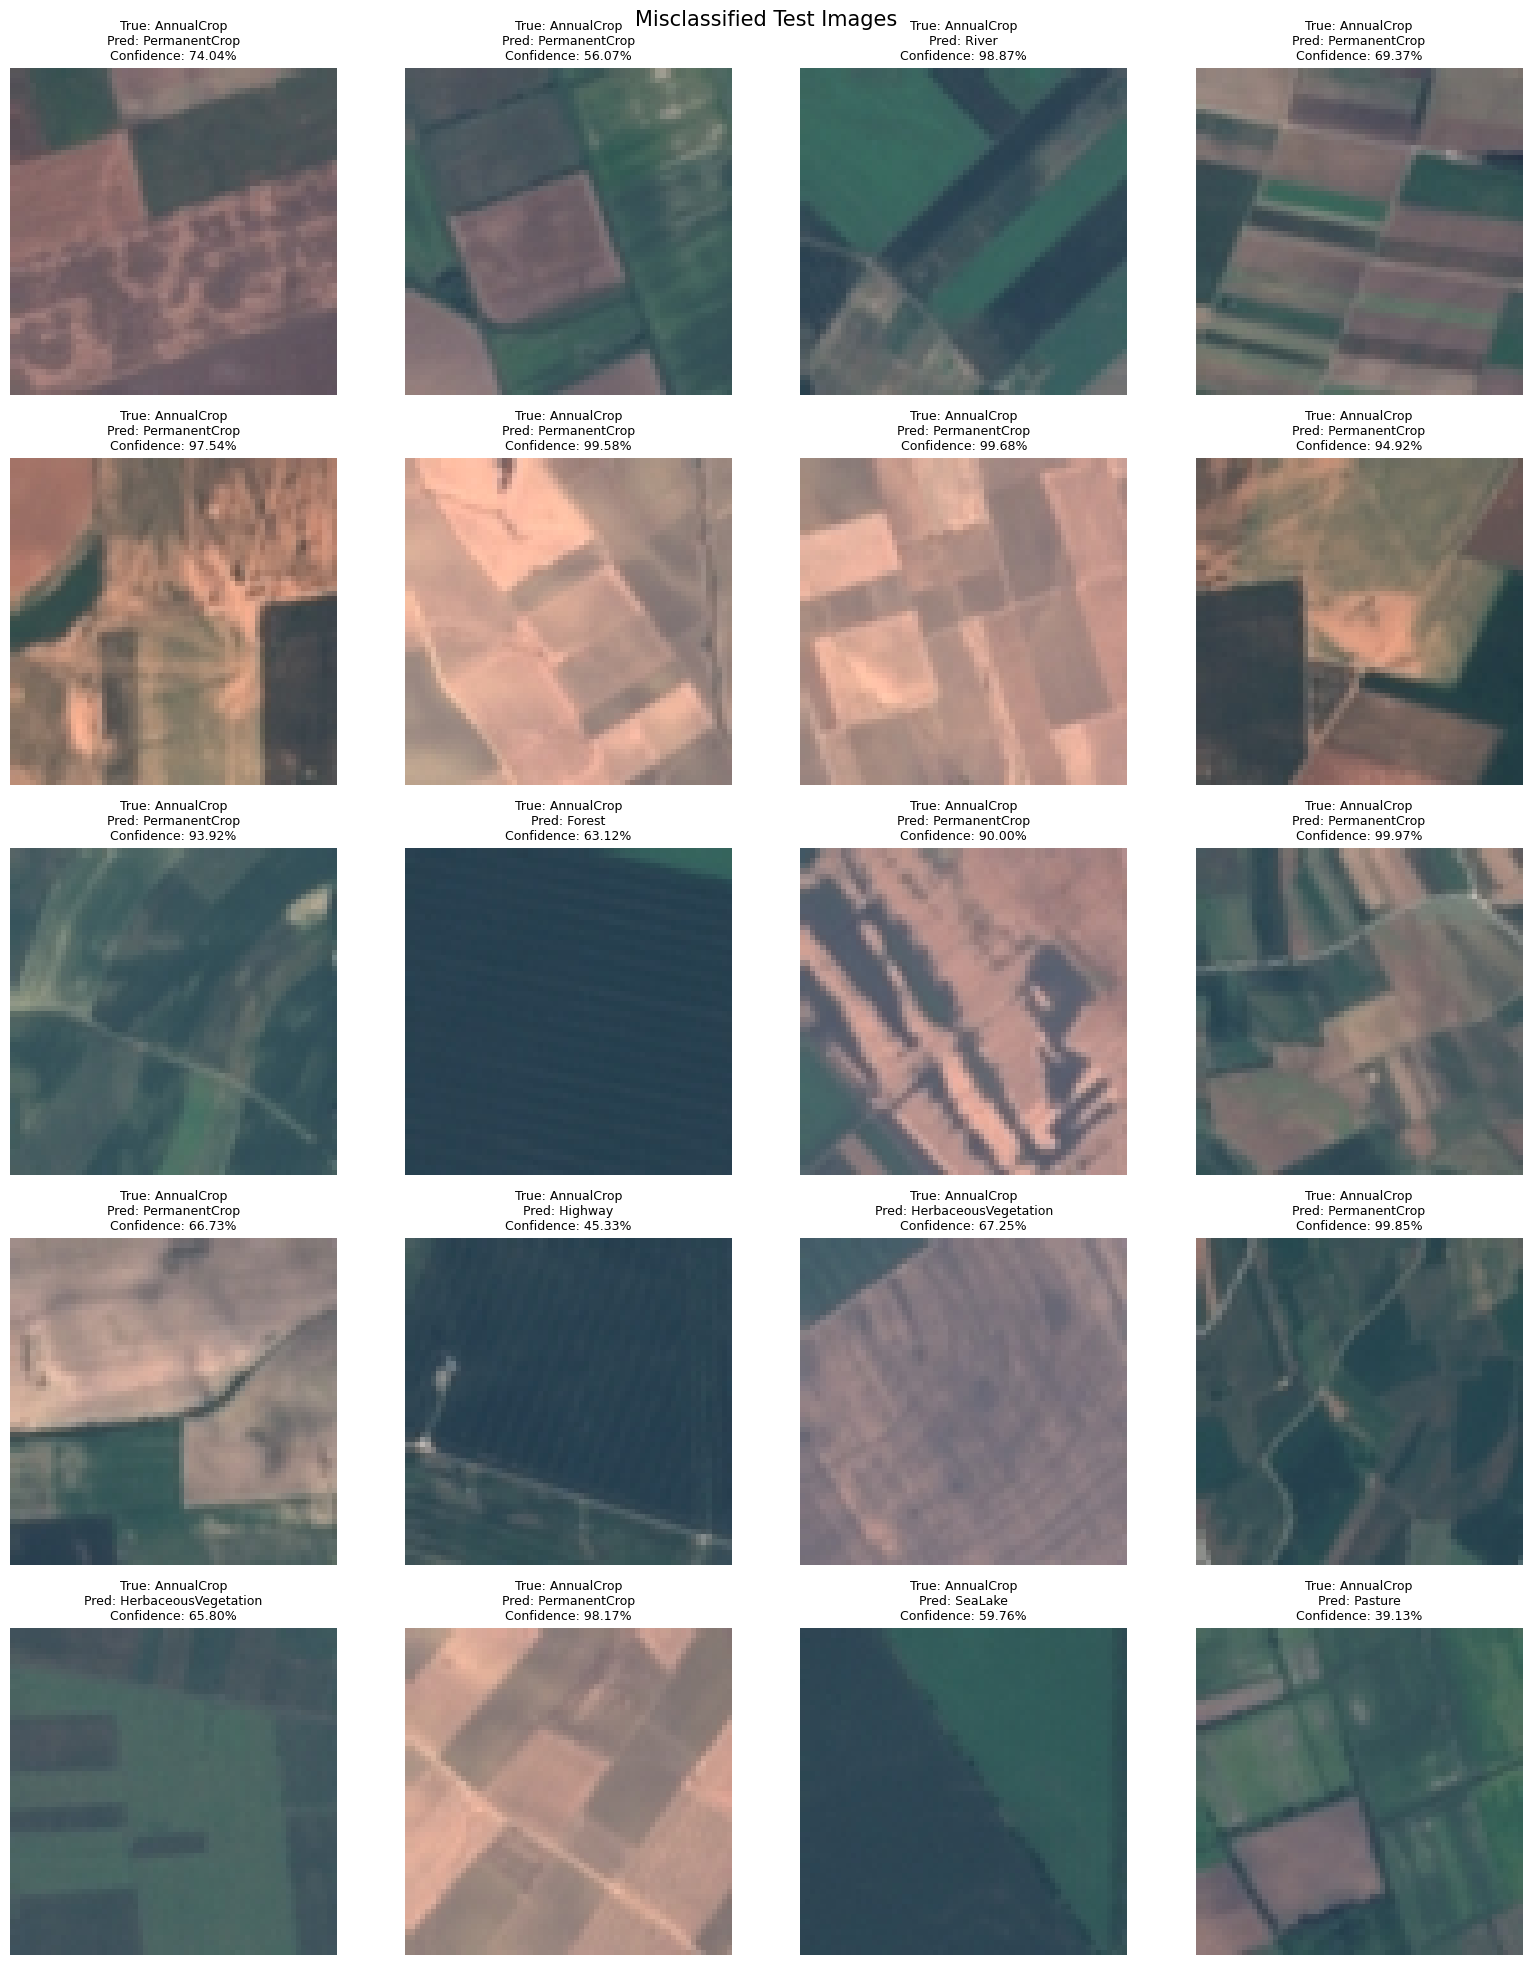

Most frequent confusion pairs (true -> predicted):
Pasture -> Forest: 32
HerbaceousVegetation -> Residential: 31
HerbaceousVegetation -> PermanentCrop: 23
AnnualCrop -> PermanentCrop: 21
Pasture -> HerbaceousVegetation: 18
Pasture -> AnnualCrop: 15
River -> AnnualCrop: 15
PermanentCrop -> HerbaceousVegetation: 14
River -> Highway: 14
Industrial -> Residential: 11


In [24]:
misclassified_idx = np.where(y_true != y_pred)[0]
print("Misclassified samples:", len(misclassified_idx), "of", len(y_true))

MAX_ERROR_IMAGES = 20
if len(misclassified_idx) == 0:
    print("هیچ نمونه اشتباهی در مجموعه Test مشاهده نشد.")
else:
    chosen = misclassified_idx[:MAX_ERROR_IMAGES]
    n_cols = 4
    n_rows = int(np.ceil(len(chosen) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, idx in zip(axes, chosen):
        image_path = test_paths_ordered[idx]
        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(
            f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}\n"
            f"Confidence: {confidence[idx]:.2%}",
            fontsize=9
        )
        ax.axis("off")
    for ax in axes[len(chosen):]:
        ax.axis("off")
    plt.suptitle("Misclassified Test Images", fontsize=15)
    plt.tight_layout()
    plt.show()

# Most frequent confusions excluding diagonal
cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)
confusion_pairs = []
for i, j in zip(*np.where(cm_offdiag > 0)):
    confusion_pairs.append((class_names[i], class_names[j], int(cm_offdiag[i, j])))
confusion_pairs = sorted(confusion_pairs, key=lambda x: x[2], reverse=True)
print("Most frequent confusion pairs (true -> predicted):")
for true_name, pred_name, count in confusion_pairs[:10]:
    print(f"{true_name} -> {pred_name}: {count}")

## ۲۱) تحلیل Confidence

Confidence در اینجا بیشترین probability خروجی Softmax برای هر تصویر است. این مقدار لزوماً احتمال کالیبره‌شده صحت پیش‌بینی نیست؛ مدل ممکن است با اطمینان بالا هم اشتباه کند.

,Group,Mean confidence,Median confidence,Count
0,Correct predictions,0.9529,0.9969,3755
1,Incorrect predictions,0.7101,0.6934,296


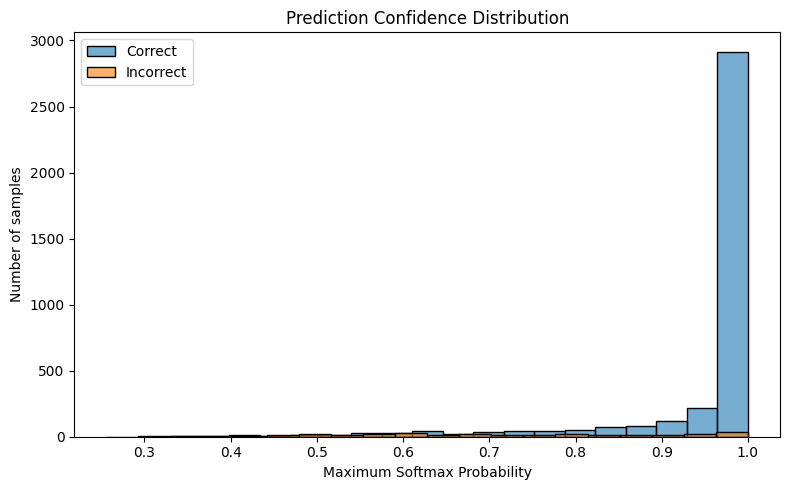

In [25]:
confidence_summary = pd.DataFrame({
    "Group": ["Correct predictions", "Incorrect predictions"],
    "Mean confidence": [
        float(confidence[y_true == y_pred].mean()) if np.any(y_true == y_pred) else np.nan,
        float(confidence[y_true != y_pred].mean()) if np.any(y_true != y_pred) else np.nan
    ],
    "Median confidence": [
        float(np.median(confidence[y_true == y_pred])) if np.any(y_true == y_pred) else np.nan,
        float(np.median(confidence[y_true != y_pred])) if np.any(y_true != y_pred) else np.nan
    ],
    "Count": [int(np.sum(y_true == y_pred)), int(np.sum(y_true != y_pred))]
})
display(confidence_summary.round(4))

plt.figure(figsize=(8, 5))
sns.histplot(confidence[y_true == y_pred], bins=20, stat="count", label="Correct", alpha=0.6)
if np.any(y_true != y_pred):
    sns.histplot(confidence[y_true != y_pred], bins=20, stat="count", label="Incorrect", alpha=0.6)
plt.xlabel("Maximum Softmax Probability")
plt.ylabel("Number of samples")
plt.title("Prediction Confidence Distribution")
plt.legend()
plt.tight_layout()
plt.show()

## ۲۲) ذخیره مدل و Metadata

مدل نهایی و metadata در `/content/models` ذخیره می‌شوند. Metadata فقط از نتایج و تنظیمات واقعی همین اجرای Notebook استفاده می‌کند.

In [26]:
FINAL_MODEL_PATH = MODEL_DIR / "eurosat_cnn.keras"
METADATA_PATH = MODEL_DIR / "model_metadata.json"

model.save(FINAL_MODEL_PATH)

metadata = {
    "project": "EuroSAT Satellite Image Classification with Custom CNN",
    "dataset": "EuroSAT RGB",
    "classes": class_names,
    "num_classes": NUM_CLASSES,
    "image_size": IMG_SIZE,
    "input_channels": 3,
    "architecture": "Custom CNN with Conv2D, BatchNormalization, ReLU, MaxPooling, Dropout, GlobalAveragePooling2D",
    "random_seed": SEED,
    "split_ratios": {
        "train": TRAIN_RATIO,
        "validation": VALIDATION_RATIO,
        "test": TEST_RATIO
    },
    "split_counts": {
        "train": int(len(train_paths)),
        "validation": int(len(val_paths)),
        "test": int(len(test_paths))
    },
    "best_validation_accuracy": float(max(history.history["val_accuracy"])),
    "best_validation_loss": float(min(history.history["val_loss"])),
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "training_seconds": float(training_seconds),
    "tensorflow_version": tf.__version__,
    "saved_at_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())
}

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

assert FINAL_MODEL_PATH.exists() and FINAL_MODEL_PATH.stat().st_size > 0
assert METADATA_PATH.exists() and METADATA_PATH.stat().st_size > 0
print("Model saved:", FINAL_MODEL_PATH, f"({FINAL_MODEL_PATH.stat().st_size:,} bytes)")
print("Metadata saved:", METADATA_PATH)

Model saved: /content/models/eurosat_cnn.keras (14,660,134 bytes)
Metadata saved: /content/models/model_metadata.json


## ۲۳) بارگذاری مجدد مدل و تست Inference

مدل ذخیره‌شده را از دیسک دوباره بارگذاری می‌کنیم و روی یک نمونه از Test پیش‌بینی می‌گیریم. این مرحله صحت ذخیره و بارگذاری را بررسی می‌کند.

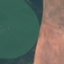

True class: AnnualCrop
Predicted class: AnnualCrop
Confidence: 99.17%


In [27]:
reloaded_model = keras.models.load_model(FINAL_MODEL_PATH)

inference_image_path = test_paths_ordered[0]
with Image.open(inference_image_path) as img:
    inference_rgb = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    display(inference_rgb)
    input_array = np.array(inference_rgb, dtype=np.float32)[None, ...]

inference_probs = reloaded_model.predict(input_array, verbose=0)[0]
inference_idx = int(np.argmax(inference_probs))
inference_conf = float(inference_probs[inference_idx])
true_class = class_names[int(y_true[0])]

assert inference_probs.shape == (NUM_CLASSES,)
assert np.isclose(inference_probs.sum(), 1.0, atol=1e-5)
assert class_names[inference_idx] in class_names

print("True class:", true_class)
print("Predicted class:", class_names[inference_idx])
print(f"Confidence: {inference_conf:.2%}")

## ۲۴) جمع‌بندی خودکار نتایج

این بخش خلاصه‌ای از نتایج واقعی اجرای Notebook را نمایش می‌دهد. از آنجا که این Notebook در زمان ساخت اجرا نشده، خروجی‌ها تنها پس از اجرای کامل در Colab قابل مشاهده خواهند بود.

In [28]:
best_val_acc = max(history.history["val_accuracy"])
best_val_loss = min(history.history["val_loss"])
best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

summary = {
    "Total validated images": len(image_records),
    "Number of classes": NUM_CLASSES,
    "Train samples": len(train_paths),
    "Validation samples": len(val_paths),
    "Test samples": len(test_paths),
    "CNN parameters": model.count_params(),
    "Best epoch (by val_loss)": best_epoch,
    "Best validation accuracy": best_val_acc,
    "Best validation loss": best_val_loss,
    "Test accuracy": test_accuracy,
    "Test loss": test_loss,
    "Training time (minutes)": training_seconds / 60
}
for key, value in summary.items():
    print(f"{key}: {value}")

Total validated images: 27000
Number of classes: 10
Train samples: 18899
Validation samples: 4050
Test samples: 4051
CNN parameters: 1209322
Best epoch (by val_loss): 12
Best validation accuracy: 0.9204938411712646
Best validation loss: 0.23960182070732117
Test accuracy: 0.926931619644165
Test loss: 0.2351776361465454
Training time (minutes): 7.4822250207265215
